# TMR4240 Project Part 2 – Mandatory Simulations & Checks

This notebook is the one place to **run the seven mandatory simulations** of
Project Part 2 and to **verify your subsystems against the automated checks**.
It is the Part 2 twin of `part_1_demo.ipynb`: each section runs a scenario
through the presets in `run_case_part_2.py` (so notebook and terminal always
run the same thing) and produces the plots the report requires; the check cells
verify the requirement-level criteria of `simulation/checks_part_2.py`.

| Section | Scenario |
|---|---|
| Subsystem checks | current, wind (gust, direction), allocation (limits), controller, reference, both observers — in isolation |
| Simulation 1 | Environmental loads: free drift, DP off — wind, current and wave signals |
| Simulation 2 | Four-corner DP test with constrained Part 2 thruster dynamics; no environment or observer |
| Simulation 3 | Four-corner DP test in the Simulation 1 environment, no observer |
| Simulation 4 | Observer selection (with / without waves), then raw vs. selected observer in closed loop |
| Simulation 5 | Average thrust-utilisation polar plot |
| Simulation 6 | Observer robustness in a heavy sea |
| Simulation 7 | Your own showcase |
| Extra credit | Sensor noise on (3 points, optional) |

Part 2 builds on Part 1. Before running anything here, move your Part 1 work
into `part_2/` following the checklist in the README (*Carrying your Part 1 work
into Part 2*): copy the implementation logic, keep the Part 2 imports and
constructor signatures, then extend wind and allocation and implement the observers.

### Setup

The presets construct every block with its **default constructor** — exactly as
the automated checks do — so keep your final tuned parameters as the defaults
in `part_2/` (see `part_2/config.py`). After Part 2, Simulation 4, set
`SELECTED_OBSERVER` in `run_case_part_2.py`; Part 2, Simulations 5–7 use it.

In [1]:
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np

import run_case_part_2 as rc
from simulation.checks import print_result
from simulation.checks_part_2 import ALL_CHECKS, run_check

results = {}  # check results, collected as you go and summarized at the end

print('Project modules imported successfully.')
print('Environment presets: current', rc.CURRENT_SPEED, 'm/s | wind', rc.WIND_SPEED,
      'm/s | waves Hs', rc.WAVES_HS, 'm, Tp', rc.WAVES_TP, 's')
print('Selected observer:', rc.SELECTED_OBSERVER)

Project modules imported successfully.
Environment presets: current 0.2 m/s | wind 10.0 m/s | waves Hs 1.5 m, Tp 8.0 s
Selected observer: kalman


## Subsystem checks — run these first

The Part 1 sign tests, re-run on the `part_2` modules, plus the explicit Part 2
requirements:

- **wind** — with `gust=True` the speed carries a zero-mean gust component on
  top of `U_mean`; with `sigma_dir > 0` the direction varies slowly and never
  leaves `dir_limit` (5°),
- **allocation** — the requested wrench is reproduced once the allocator has
  converged through ideal actuators (a steady-state allocator on its first call,
  a rate-aware one within a few seconds), and every command stays within `u_max`,
  also for an infeasible demand,
- **thrust utilisation** — the two functions of `part_2/utilization.py` on a
  synthetic log (definition and averaging window),
- **observers** — from pose measurements only: finite output, a velocity estimate
  of the right sign during a drift, wave-frequency content reduced, and a heading
  estimate that survives the $\pm\pi$ crossing.

These are requirement checks, not a grade: how *well* the observer filters and
how accurately the loop holds position is what you analyse in the report. Each
check reports `NOT IMPLEMENTED` while the template placeholder is in place.

In [2]:
for key in ALL_CHECKS:
    results[key] = run_check(key)
    print_result(results[key])
    print()

[     PASS      ] current (part_2): direction conventions
                  ok    from east -> flows west: [V_N, V_E] = [0, -0.5]  [got [-0.  -0.5]]
                  ok    components 2-5 of the generalized vector are zero  [got [0. 0. 0. 0.]]
                  ok    rotation start: from north -> [-0.5, 0]  [got [-0.5  0. ]]
                  ok    rotation end: from east -> [0, -0.5]  [got [-0.  -0.5]]

[     PASS      ] wind (part_2): loads, gust, direction variation
                  ok    gust off, head wind: Fx < 0 and |Fx| = U^2*Cx(180 deg) within 5%  [Fx = -2.86 kN vs expected -2.86 kN]
                  ok    gust off, wind from east at psi=0: Fy < 0 and dominant  [Fx = -0.00 kN, Fy = -10.92 kN]
                  ok    relative wind: sailing into the wind increases |Fx|  [Fx = -4.12 kN moving vs -2.86 kN at rest]
                  ok    gust=False (default): U_gust is identically zero  [max |U_gust| = 0.000 m/s]
                  ok    sigma_dir=0 (default): direction is consta

## Part 2, Simulation 1 — Environmental Loads

DP off (`use_controller=False`): the vessel drifts under current, wind and
waves for 300 s. Besides position, heading and the $xy$-plot, the preset plots
the signals you built — total wind speed, its mean+slow part and the gust, wind direction (bounded
variation), current components and the wave loads — so the environmental model
itself is demonstrated. Discuss the drift against the environment set at the
top of `run_case_part_2.py`.

drift after 300 s: N = -134.4 m, E = -104.6 m, psi = -76.0 deg


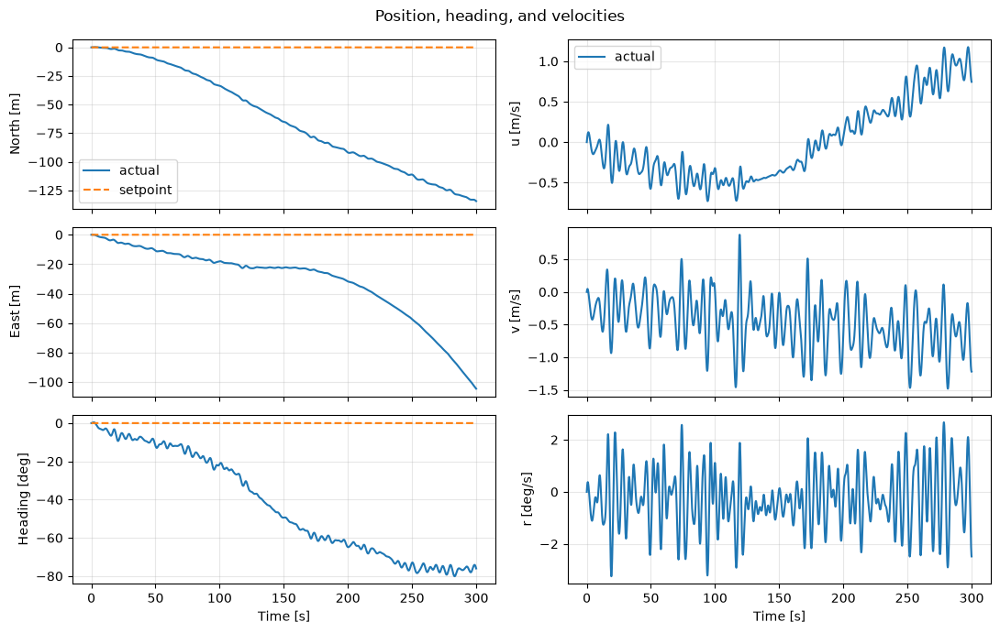

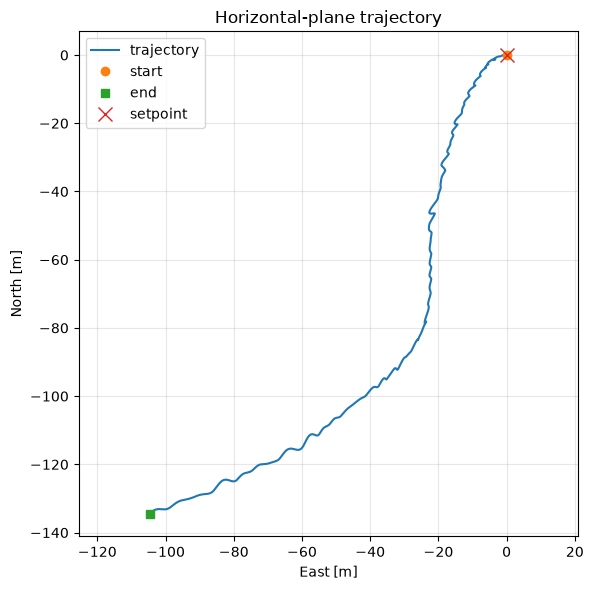

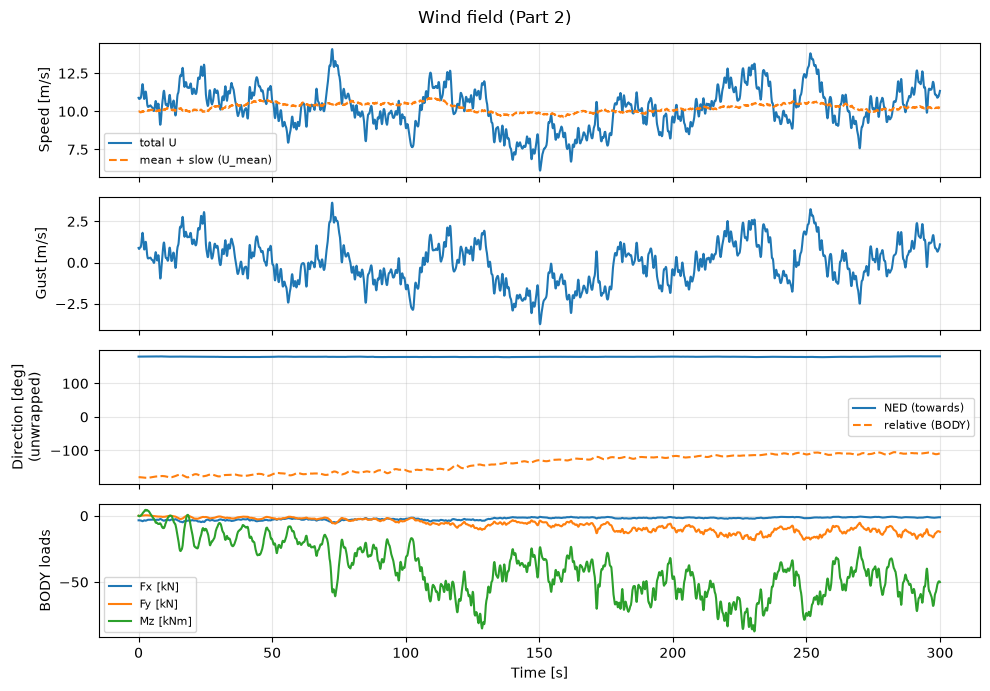

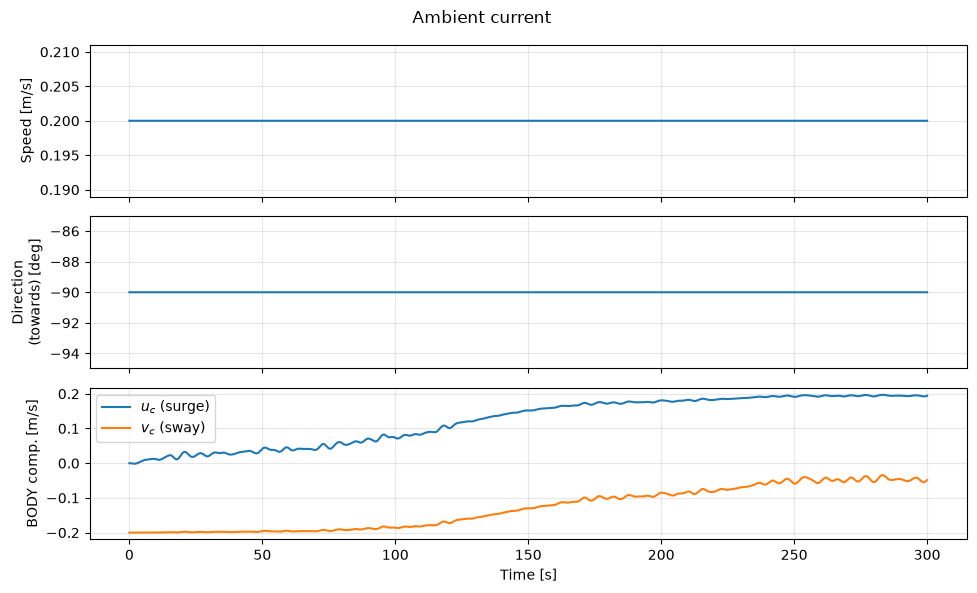

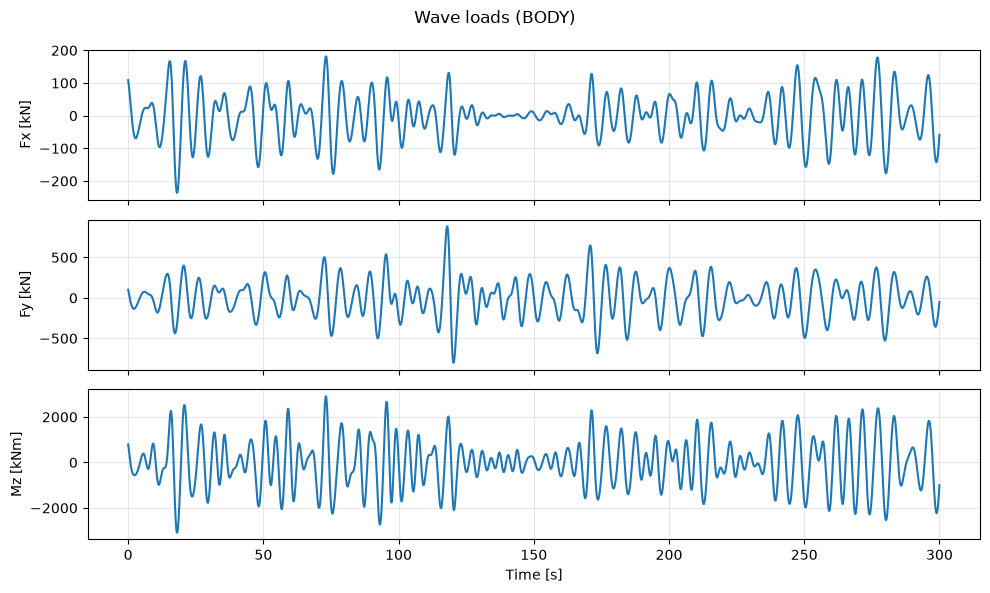

In [3]:
logs_1 = rc.sim1()
print(f'drift after {logs_1.t[-1]:.0f} s: N = {logs_1.eta[-1, 0]:.1f} m, E = {logs_1.eta[-1, 1]:.1f} m, '
      f'psi = {np.rad2deg(logs_1.eta[-1, 5]):.1f} deg')



## Part 2, Simulation 2 — Thrust Allocation and Thruster Dynamics

Run the Part 1 four-corner trajectory with the reference model, controller,
allocator, and constrained Part 2 thruster dynamics enabled. Current, wind,
waves, and the observer are disabled. Compare the desired controller wrench
with the applied thruster wrench and inspect each thruster's commanded and
actual thrust and azimuth. Discuss tracking, settling, allocation accuracy,
and any intervals in which an actuator constraint is active.

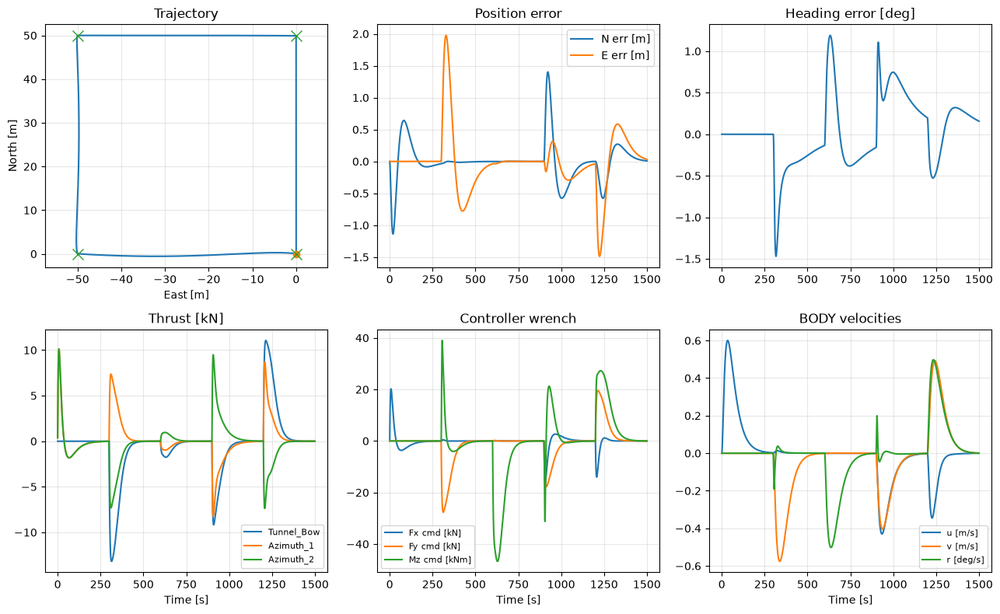

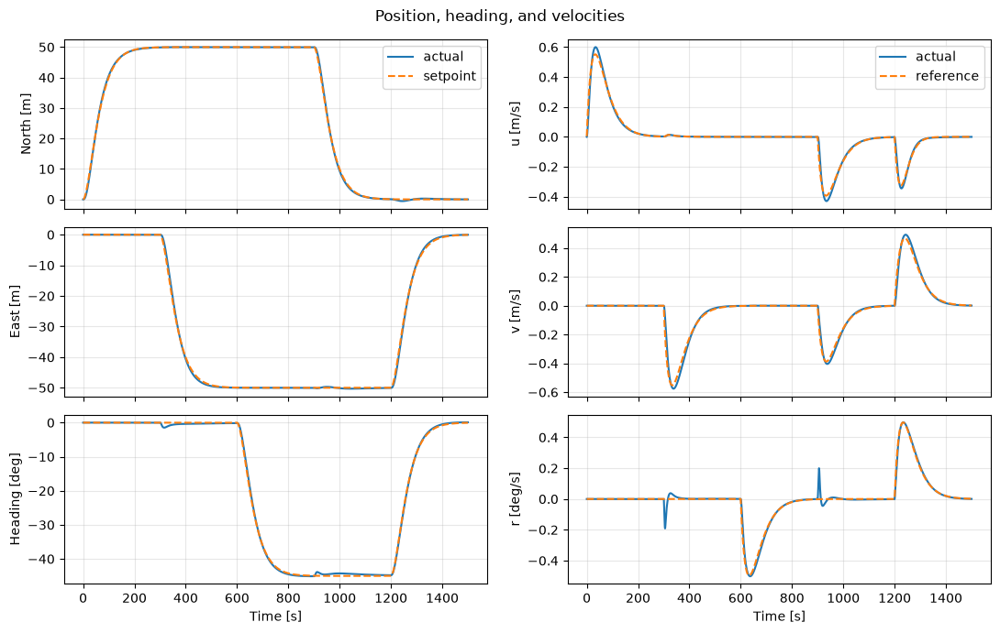

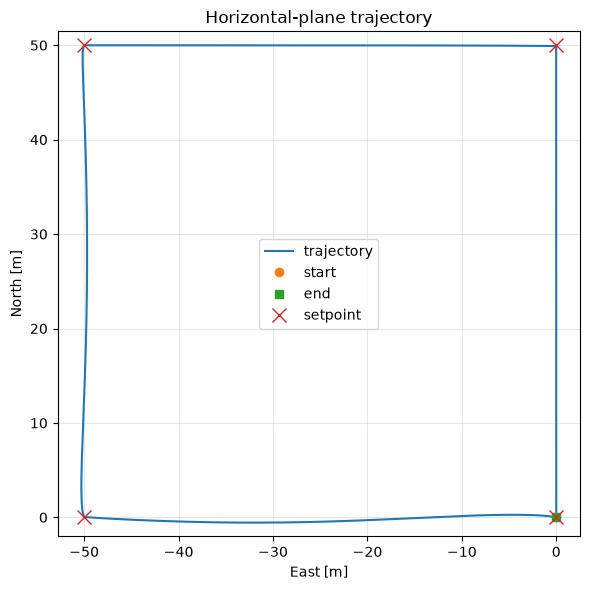

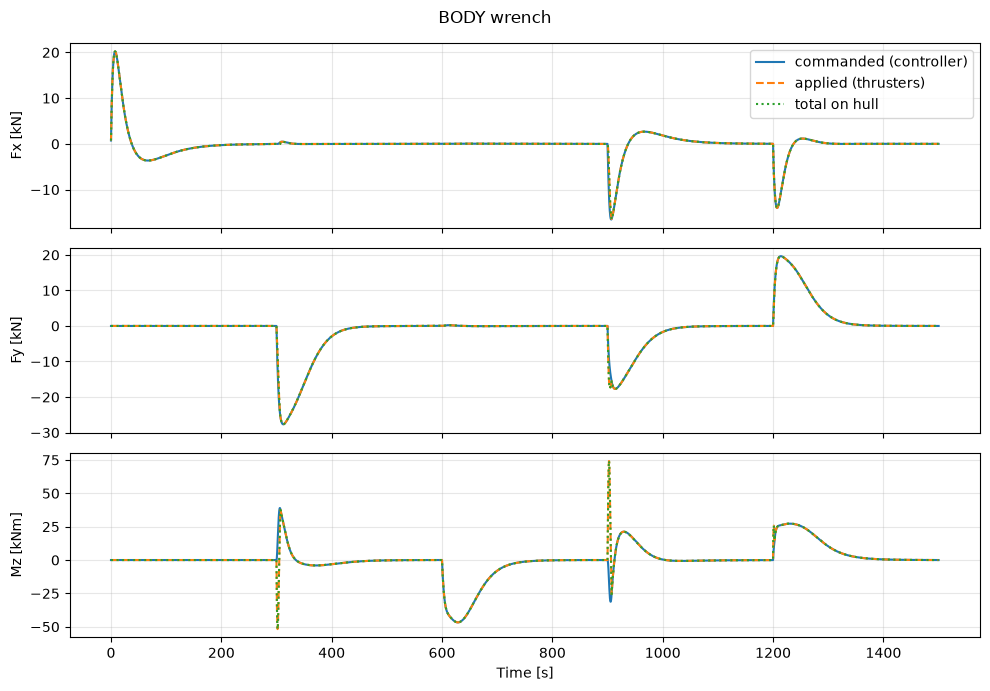

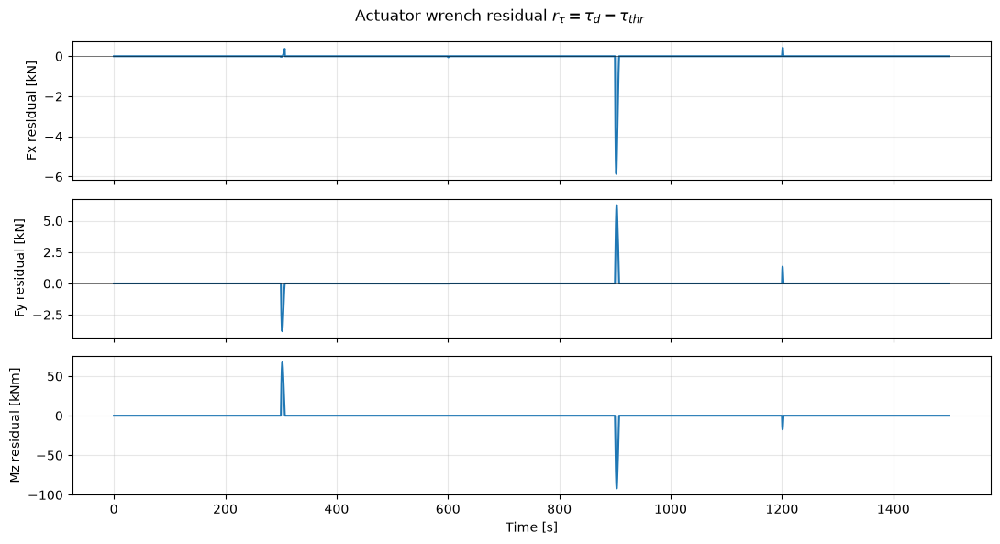

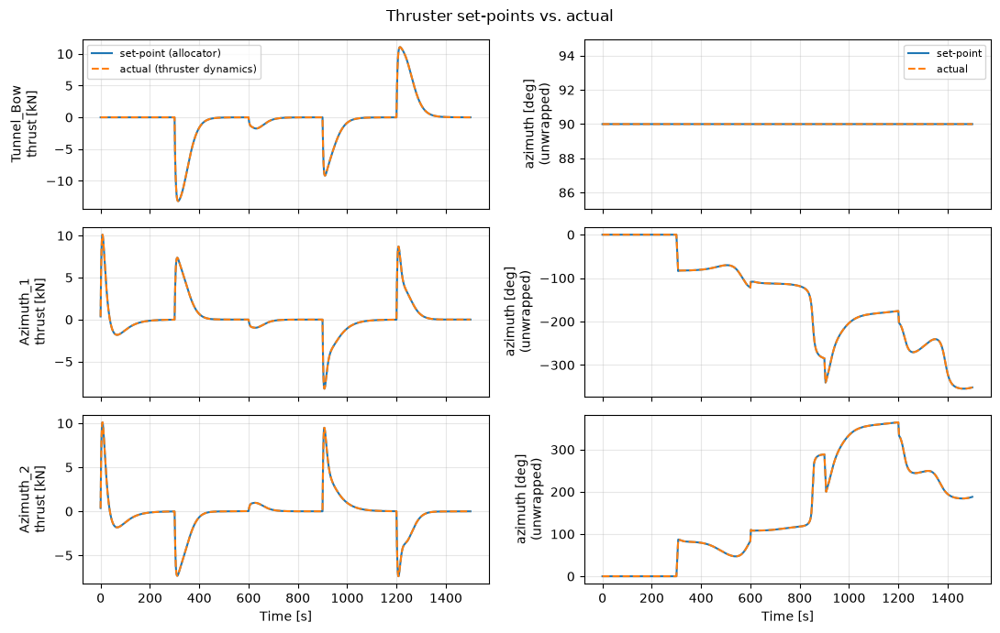

In [4]:
logs_2 = rc.sim2()

## Part 2, Simulation 3 — Four-Corner DP Test With Environmental Loads

Repeat the prescribed four-corner trajectory in the Part 2, Simulation 1
environment: current from east, gusty wind from north, and waves from
north-east. The reference model and constrained thrusters are on, while raw
measurements are fed back (no observer). Compare tracking and actuator use
with Part 2, Simulation 2. This is the full-environment baseline before
observer feedback is introduced in Simulation 4.

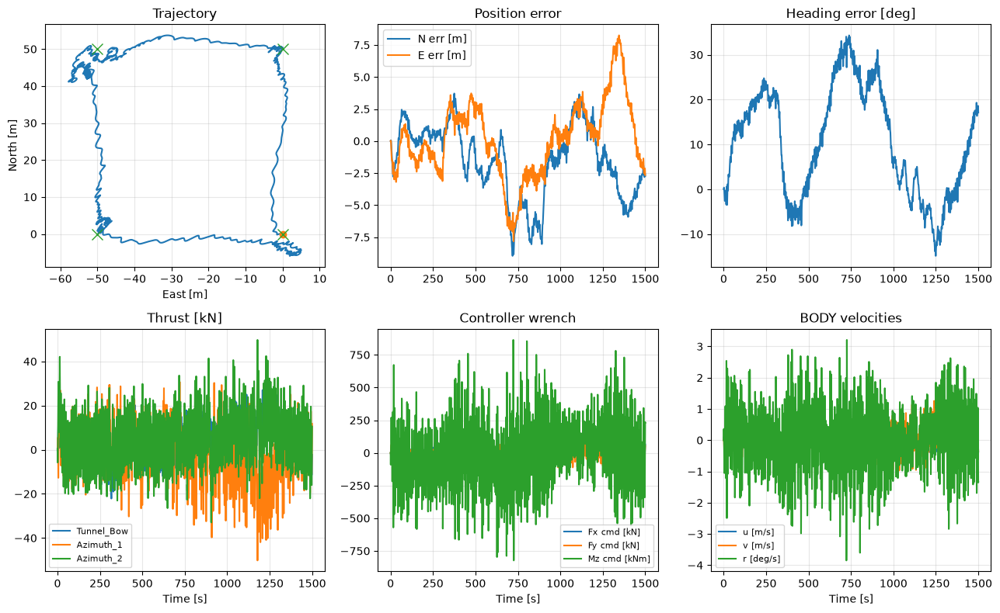

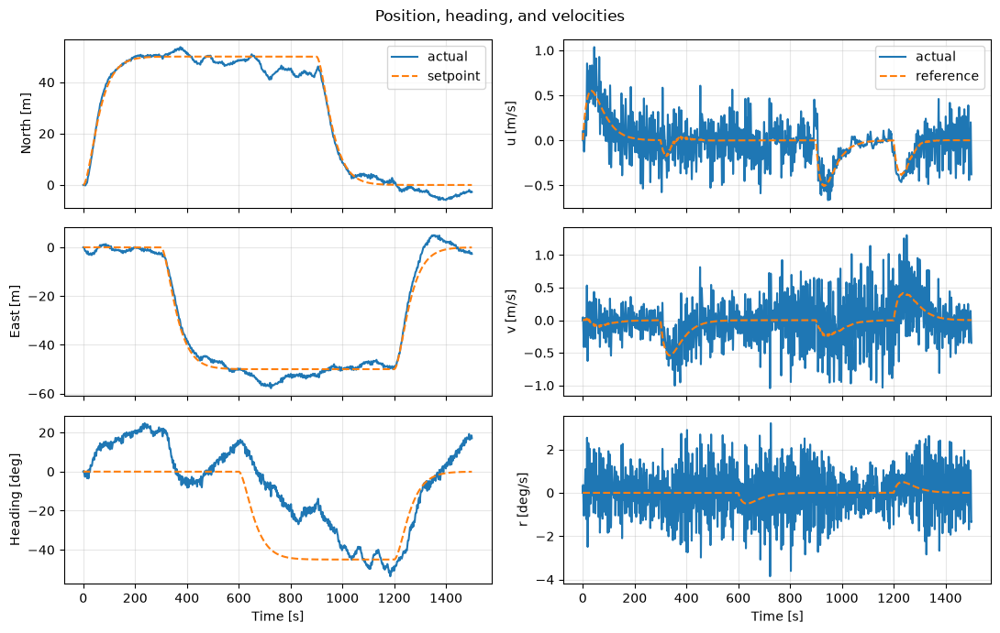

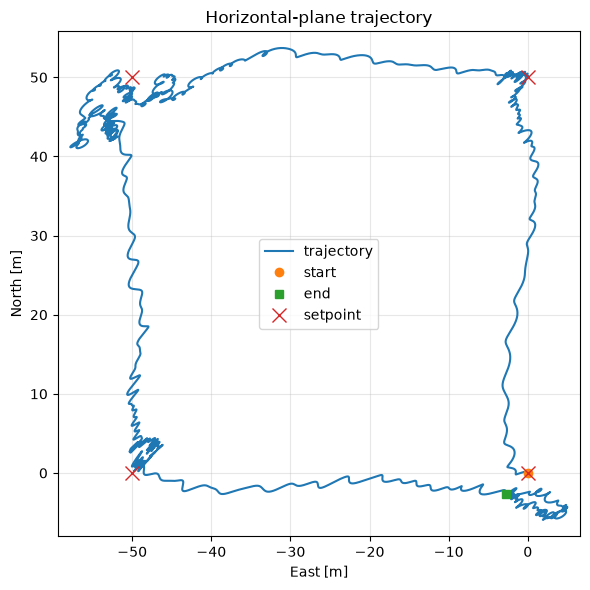

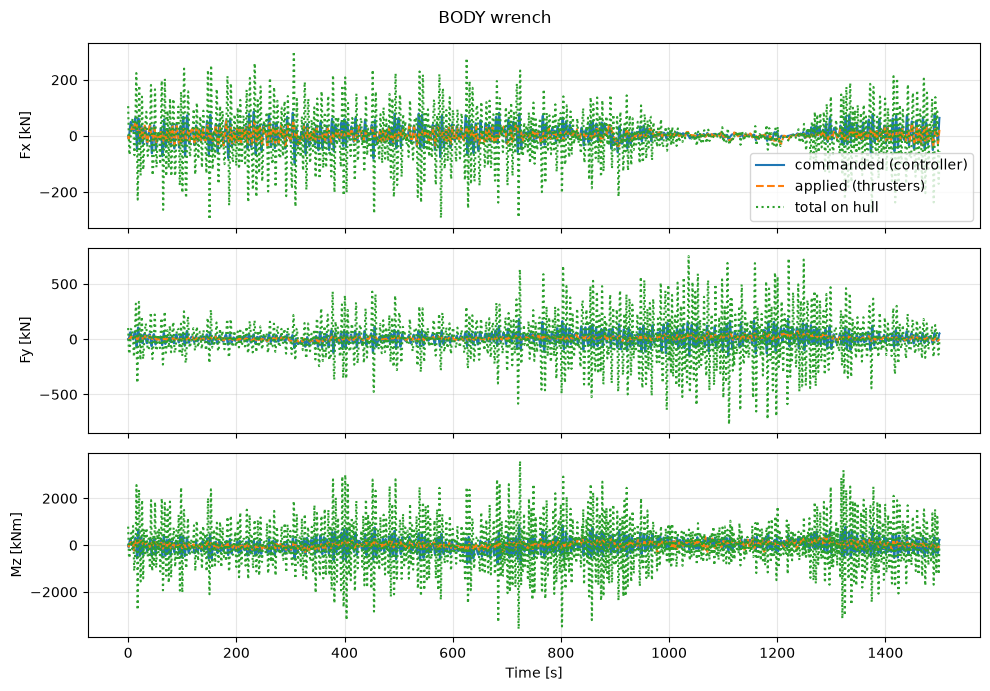

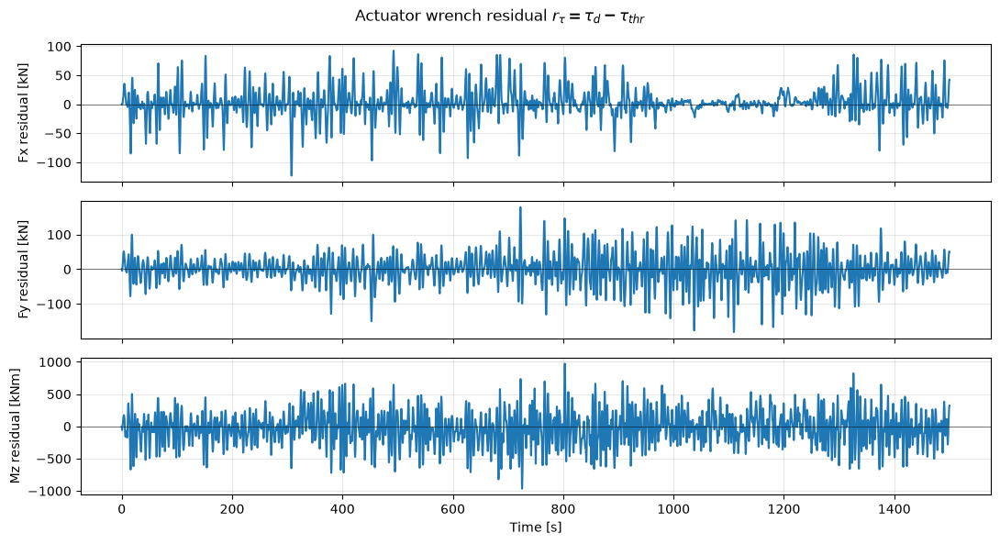

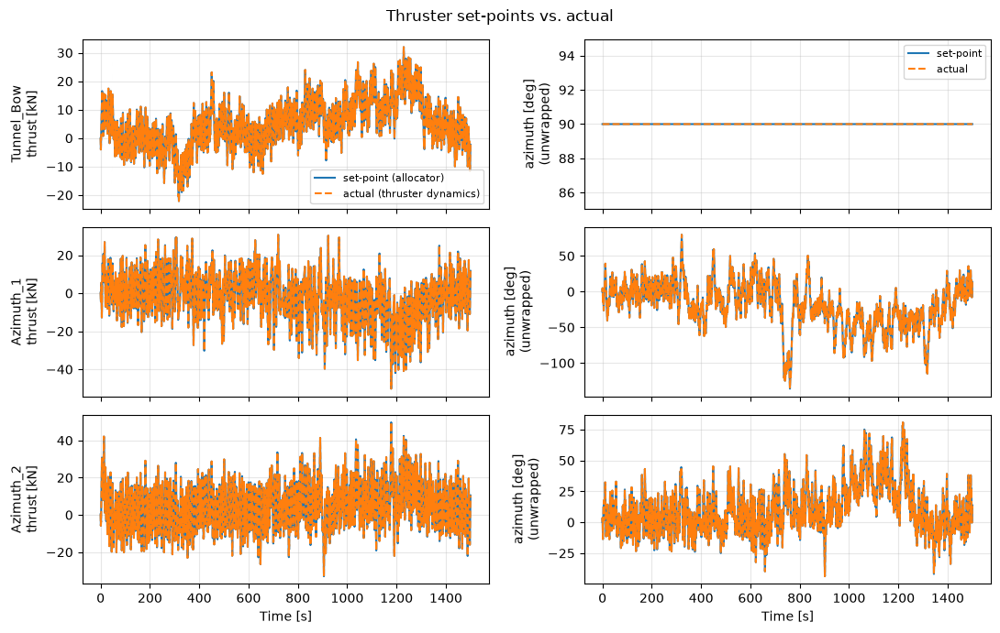

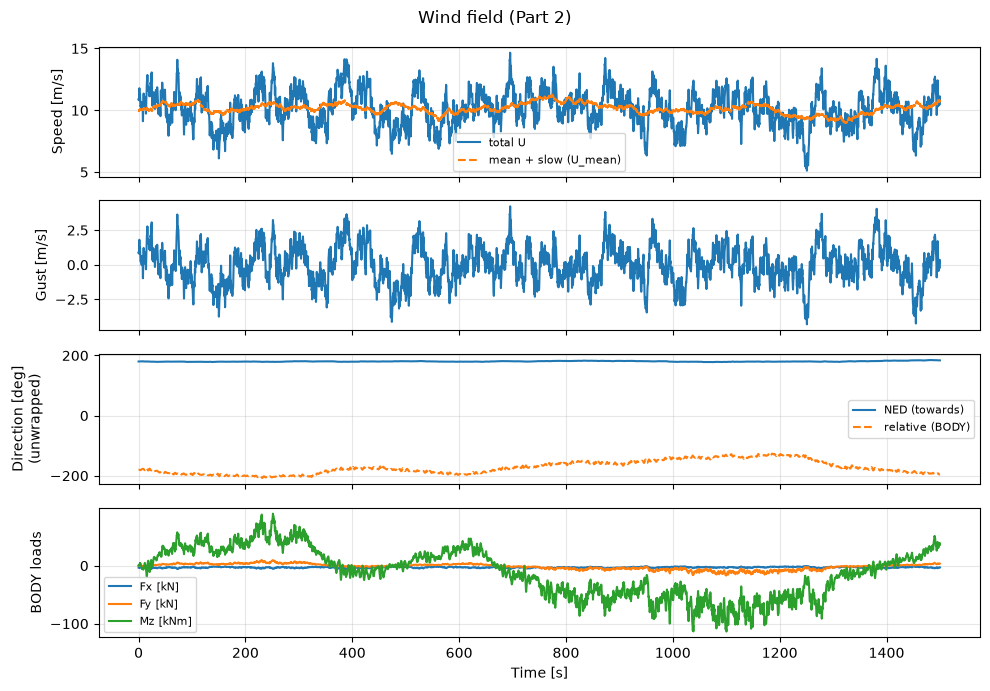

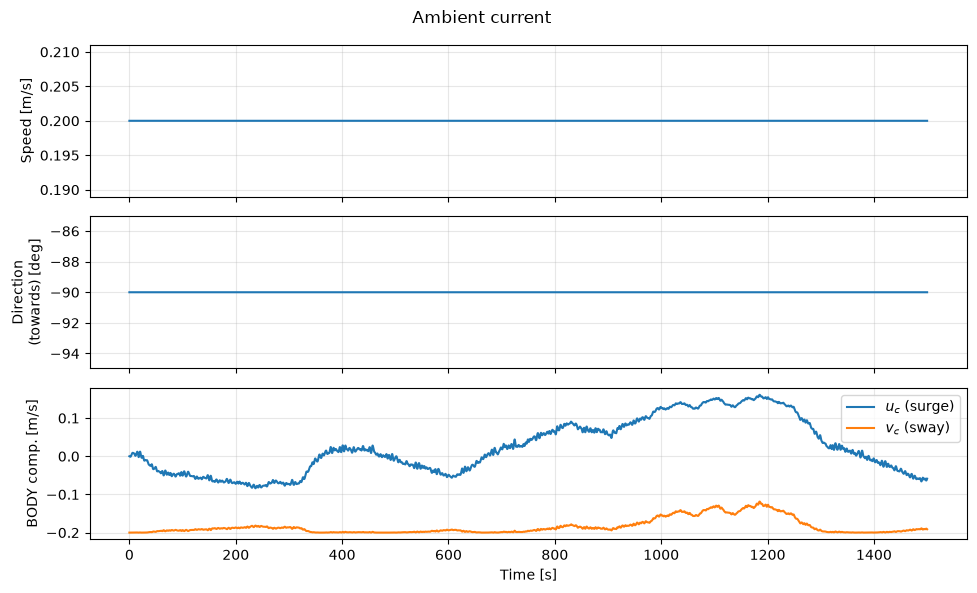

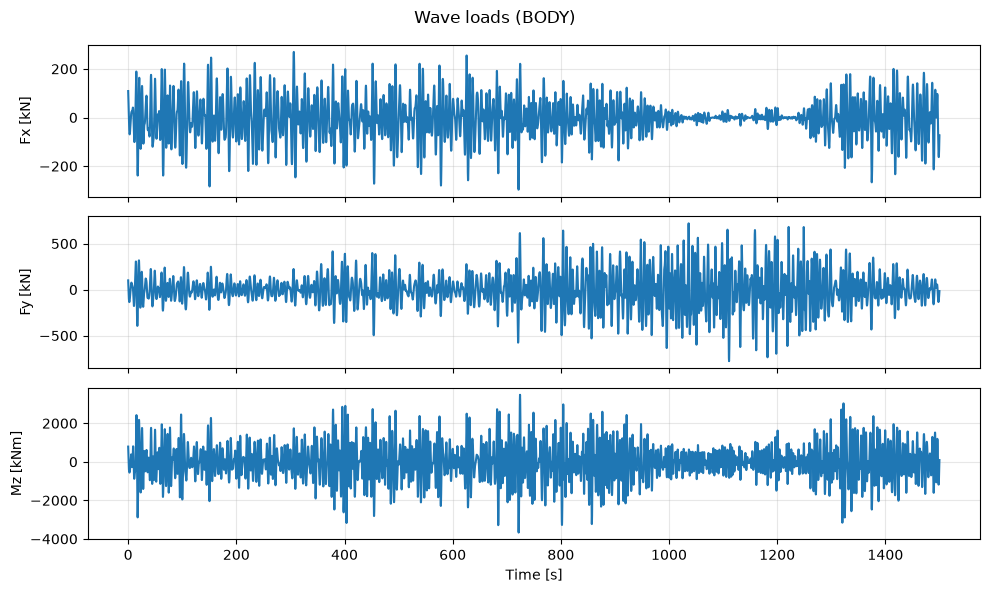

In [5]:
logs_3 = rc.sim3()

## Part 2, Simulation 4 — Observer Selection

A fixed desired wrench $[2, 2, 2]\cdot 10^3$ replaces the controller. Both
observers run in the Part 2, Simulation 1 environment **with waves** and **without
waves** (ideal measurements). Compare estimates with the true states and
choose your observer — then set `SELECTED_OBSERVER` in `run_case_part_2.py`.
The `plot_observer_error` figures (estimate − truth and estimate − 30-s mean of
the truth) are where the wave filtering is visible; the overlay plots mostly show
the drift of the uncontrolled vessel.

The preset ends with the closed loop: station keeping in the same environment
with **raw measurements** vs. **the selected observer**. This is the evidence
that the observer improves the DP system — compare position error, thruster
activity and utilisation.

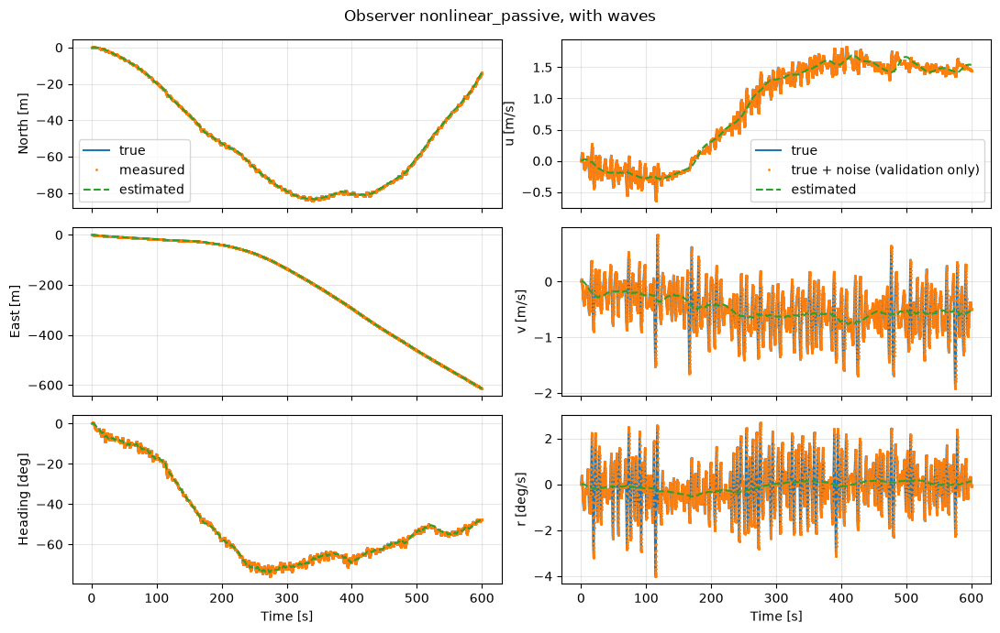

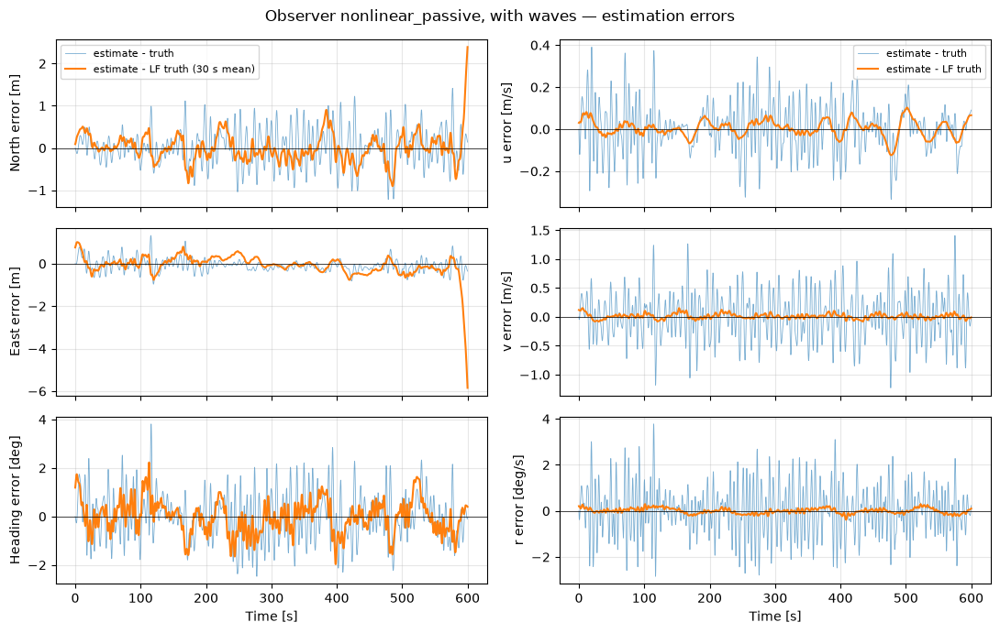

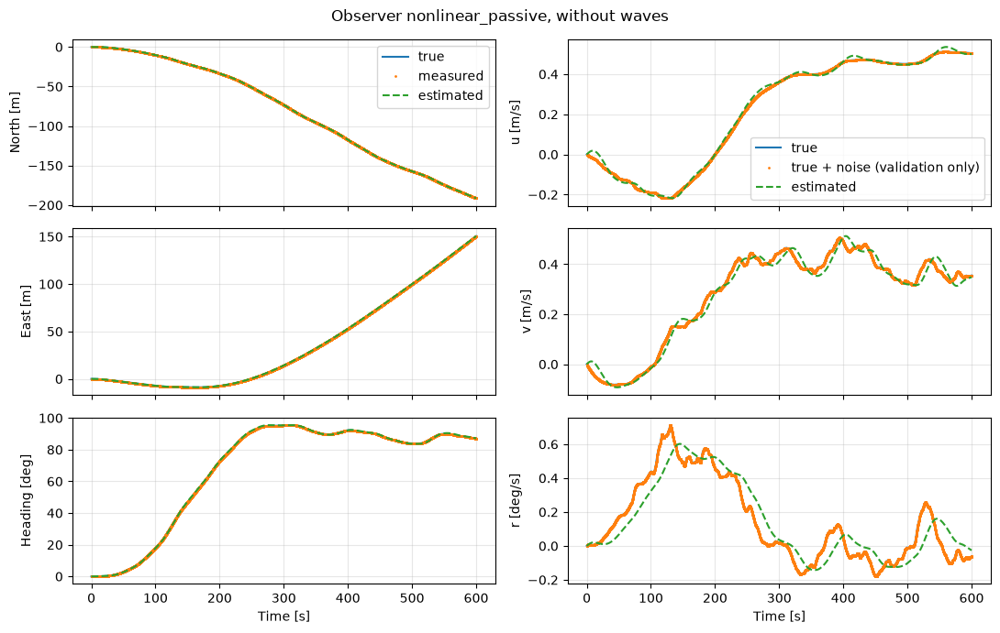

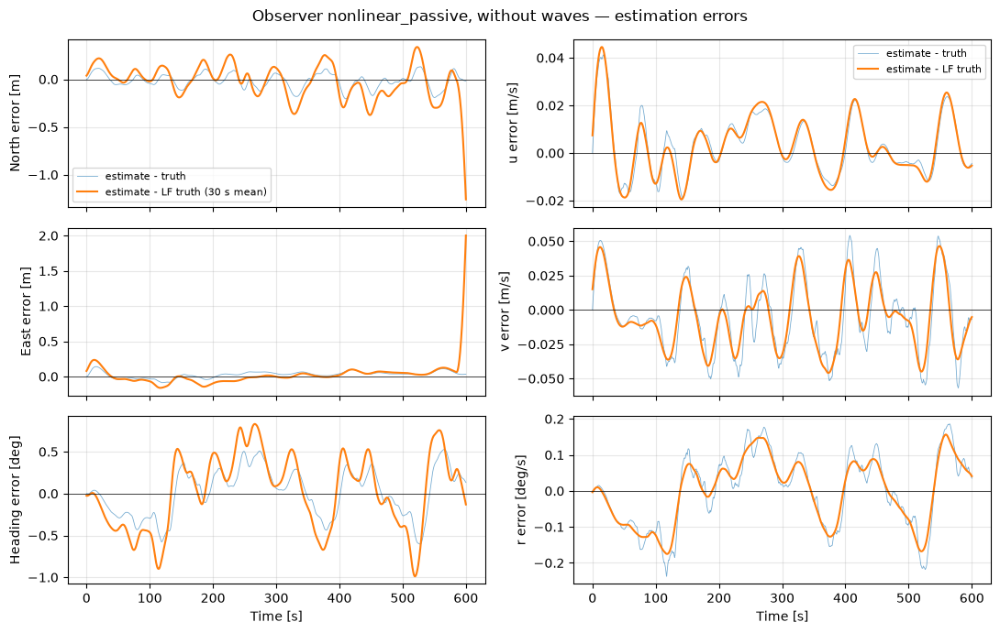

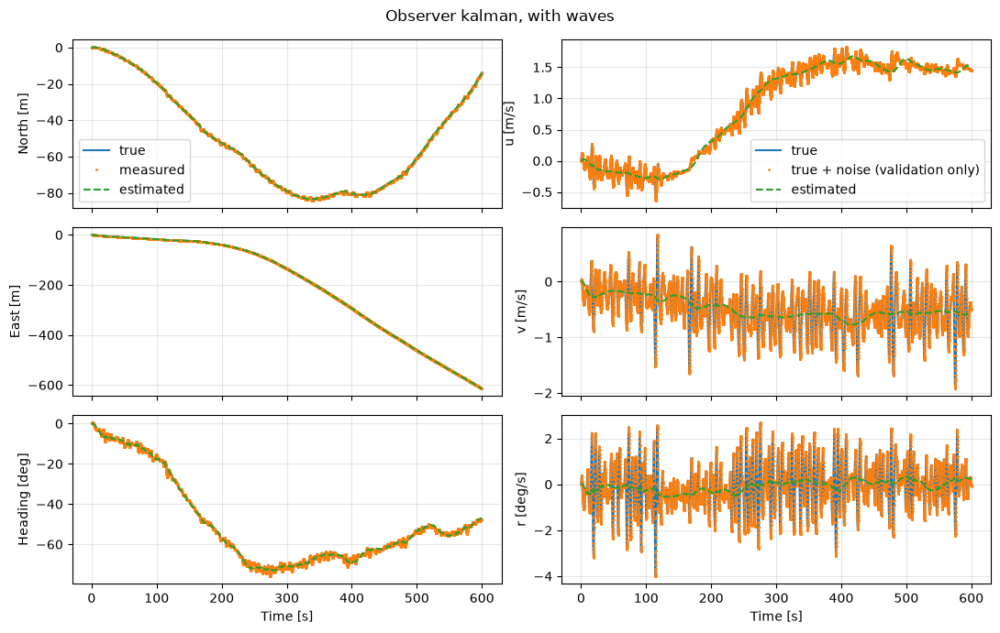

...

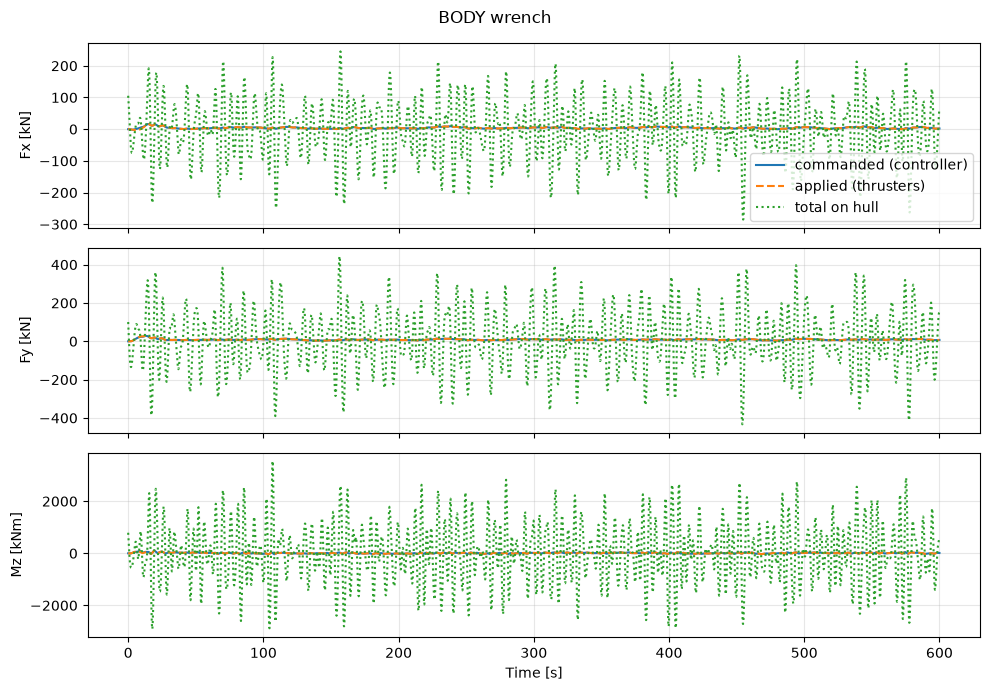

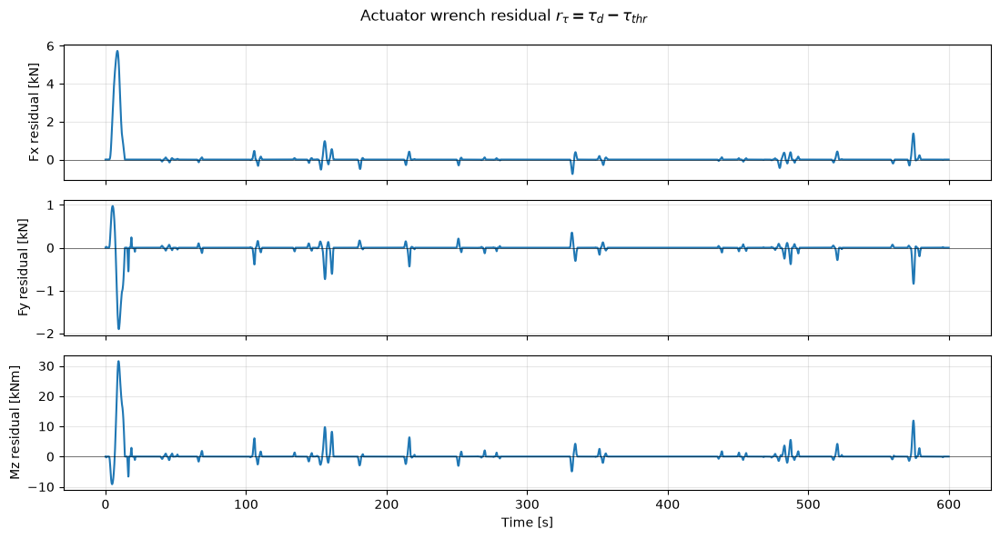

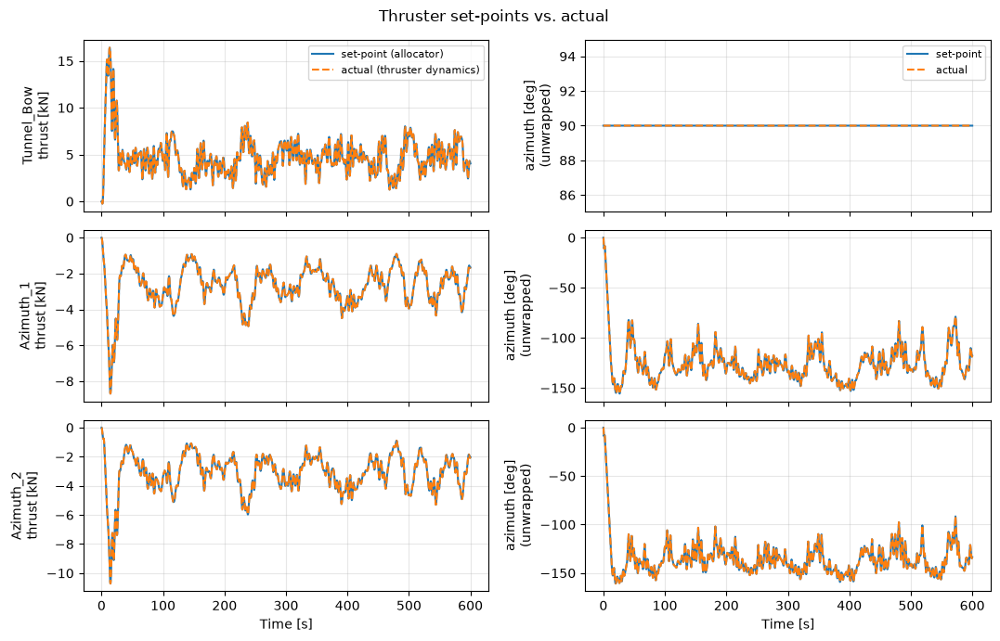

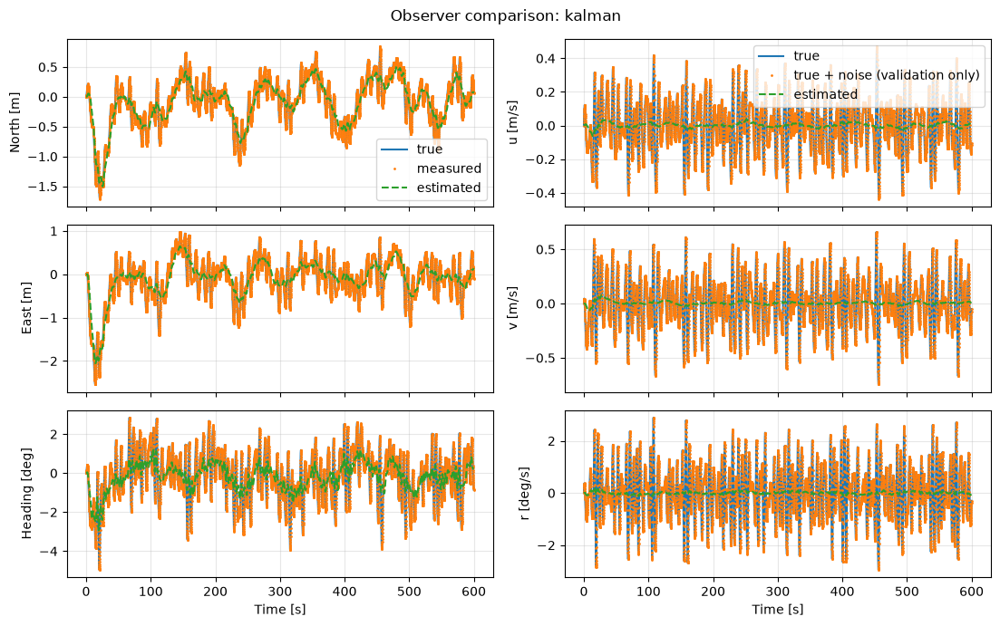

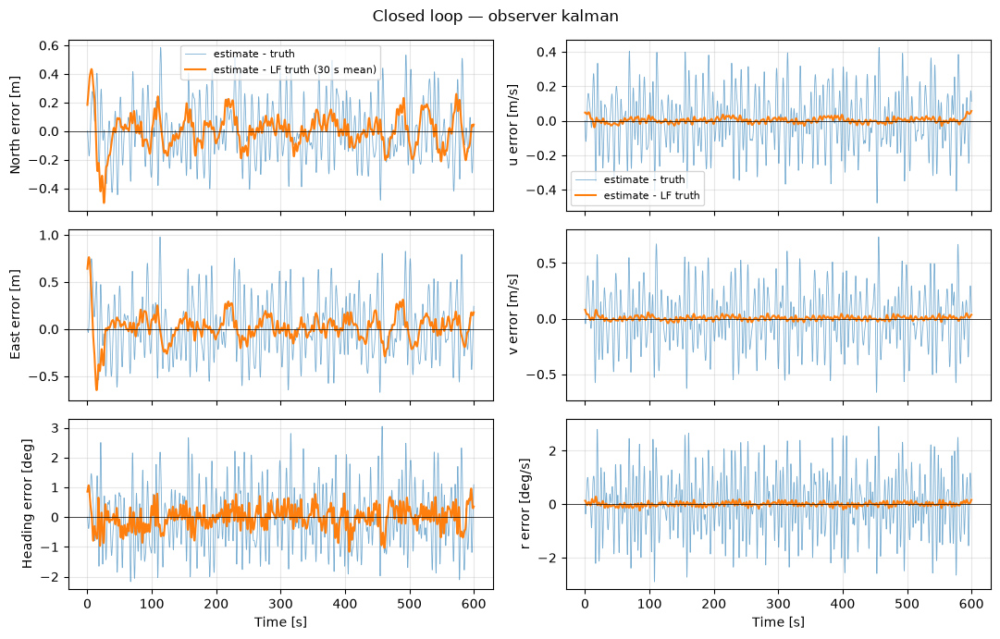

In [6]:
logs_4 = rc.sim4()   # dict keyed by (observer, variant) and ('closed loop', ...)

## Part 2, Simulation 5 — Average Thrust-Utilisation Polar Plot

Co-linear wind, waves and current swept around the vessel in 10° steps while
the DP system (with `SELECTED_OBSERVER`) holds the origin at heading 0.
`simulation/capability.py` computes, per direction, the average thrust
utilisation $\bar U_T = \mathrm{mean}\big(100\,\sum_i|u_i|/\sum_i u_{i,\max}\big)$
over the post-settling window and draws three polar plots: all directions;
the DP watch-circle view, which masks a direction whose maximum
**low-frequency** excursion (30 s moving average, second half of the run)
exceeds 5 m / 5° — the station-keeping motion a DP system checks on its
screen; and the operability view, which masks a direction whose maximum
**total** motion (wave-frequency oscillation included) exceeds 3 m / 3° —
what a connected gangway experiences. Both deviations are printed per
direction: discuss the two masked plots against each other. The utilisation metrics
(`thrust_utilization`, `average_utilization`) are **yours to implement** in
`part_2/utilization.py` — this cell tells you so until you do. The full
sweep is 36 runs; use a coarser step while developing.

direction   0.0 deg: utilisation   3.8 %, max total dev 1.39 m / 0.86 deg, max LF dev 0.93 m / 0.73 deg -> ok (lf)
direction  10.0 deg: utilisation   5.4 %, max total dev 1.43 m / 4.08 deg, max LF dev 1.01 m / 2.30 deg -> ok (lf)
direction  20.0 deg: utilisation   7.1 %, max total dev 1.87 m / 6.29 deg, max LF dev 1.29 m / 3.53 deg -> ok (lf)
direction  30.0 deg: utilisation   8.9 %, max total dev 2.52 m / 7.18 deg, max LF dev 1.63 m / 4.07 deg -> ok (lf)
direction  40.0 deg: utilisation  11.2 %, max total dev 3.00 m / 6.42 deg, max LF dev 2.01 m / 3.89 deg -> ok (lf)
direction  50.0 deg: utilisation  12.5 %, max total dev 2.78 m / 6.39 deg, max LF dev 1.85 m / 3.79 deg -> ok (lf)
direction  60.0 deg: utilisation  13.3 %, max total dev 3.13 m / 6.13 deg, max LF dev 2.12 m / 3.57 deg -> ok (lf)
direction  70.0 deg: utilisation  14.4 %, max total dev 3.22 m / 5.41 deg, max LF dev 2.31 m / 3.27 deg -> ok (lf)
direction  80.0 deg: utilisation  15.5 %, max total dev 3.32 m / 3.15 deg, max L

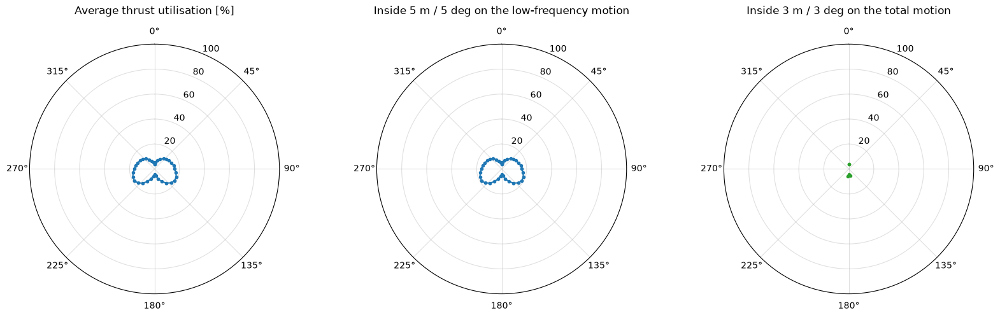

In [7]:
try:
    cap = rc.sim5(step_deg=10.0)
    print('feasible directions [deg]:', cap.directions_deg[cap.feasible])
except NotImplementedError as exc:
    print('SKIPPED —', exc)


## Part 2, Simulation 6 — Observer Robustness

Station keeping at the origin for 1000 s in the heavy sea (`ROBUST_HS`,
`ROBUST_TP`) with `SELECTED_OBSERVER` in the loop; current and wind as in
Part 2, Simulation 1.

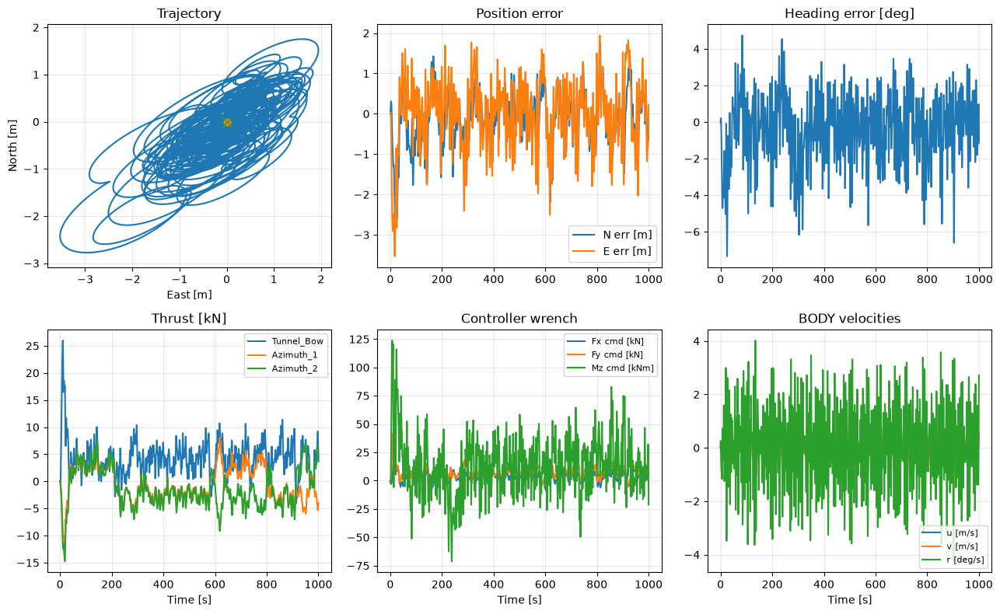

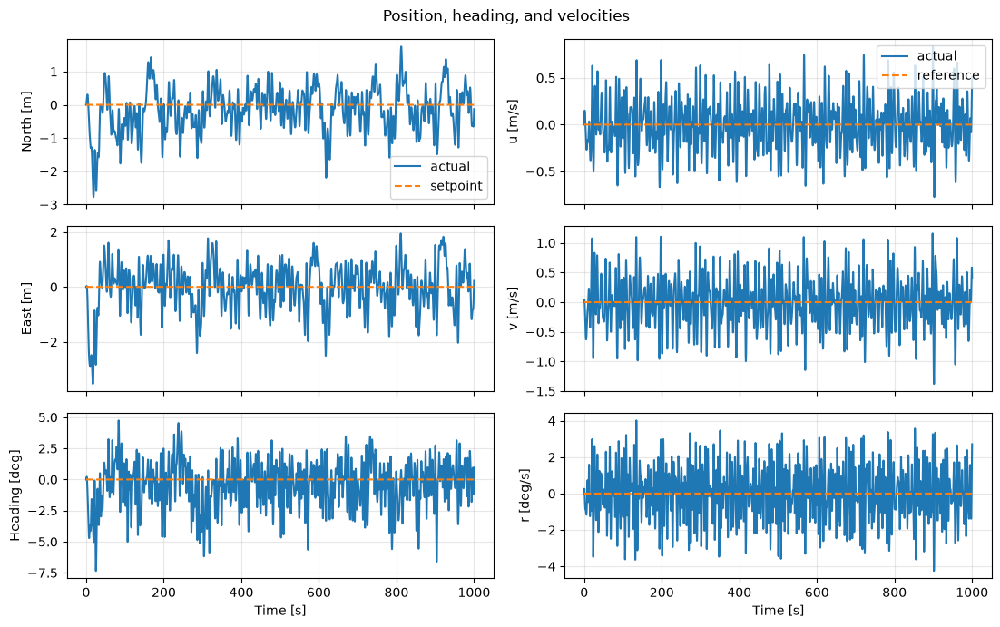

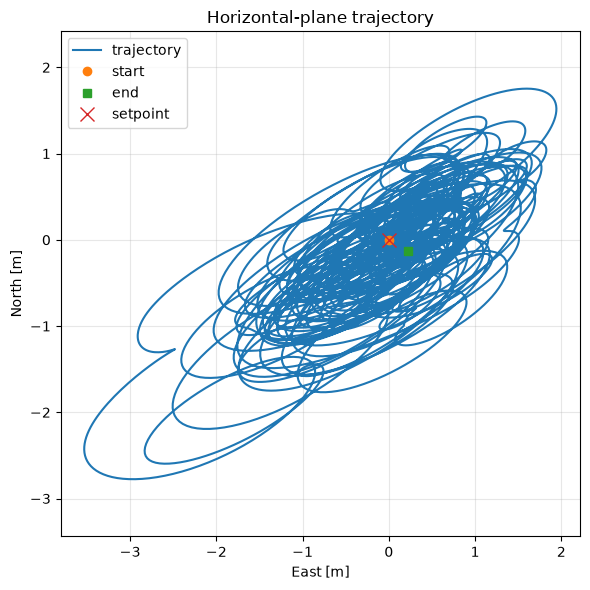

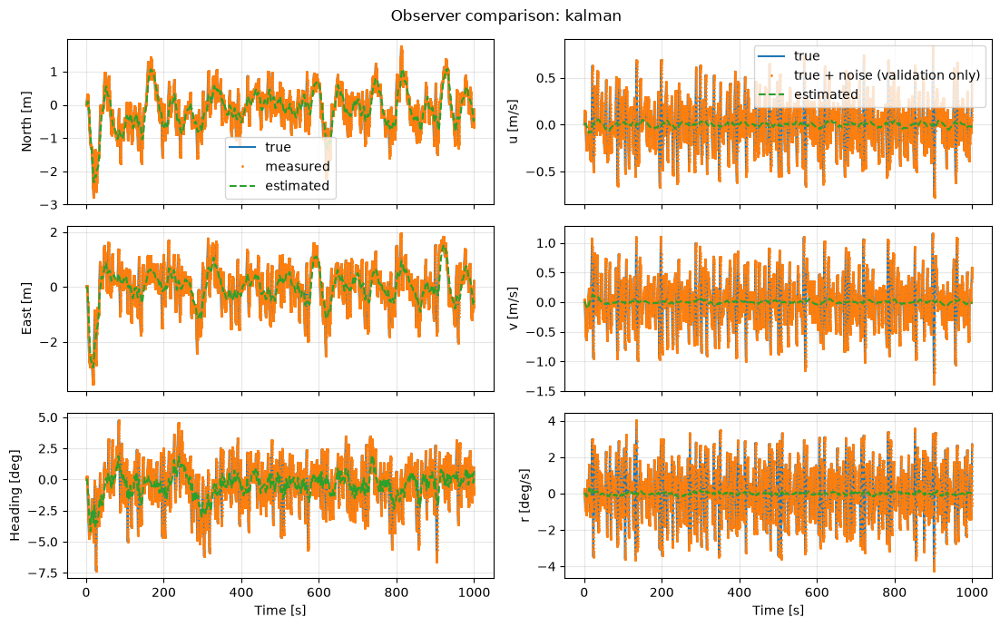

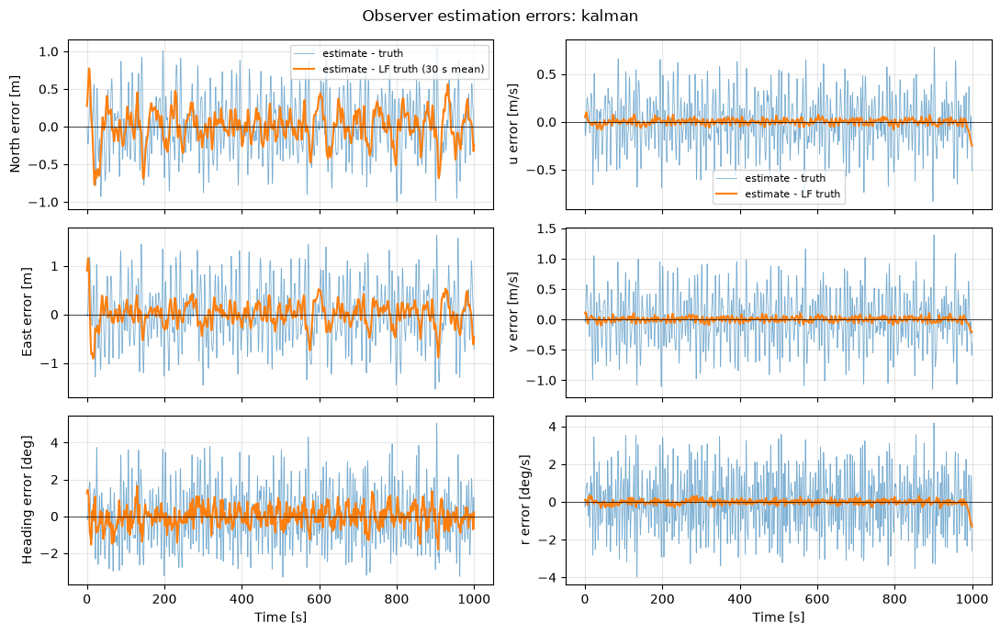

In [8]:
try:
    logs_6 = rc.sim6()
except NotImplementedError as exc:
    print('SKIPPED —', exc)

## Part 2, Simulation 7 — Your Own Showcase

Design a simulation that shows the strengths **and** the limits of your DP
system; edit `sim7()` in `run_case_part_2.py`, explain the scenario and its
parameters, and discuss the result.

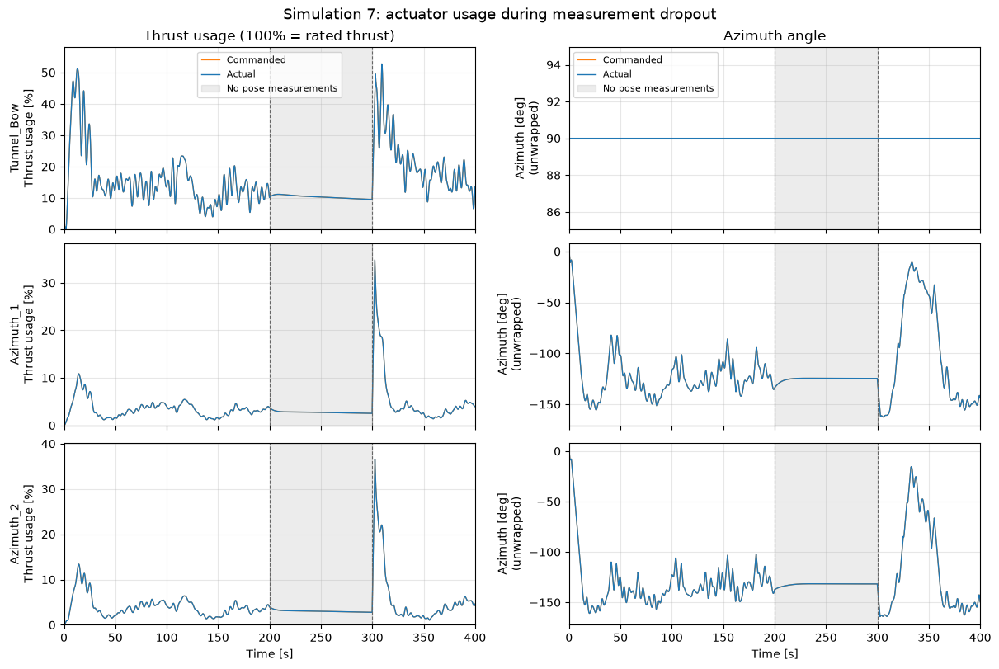

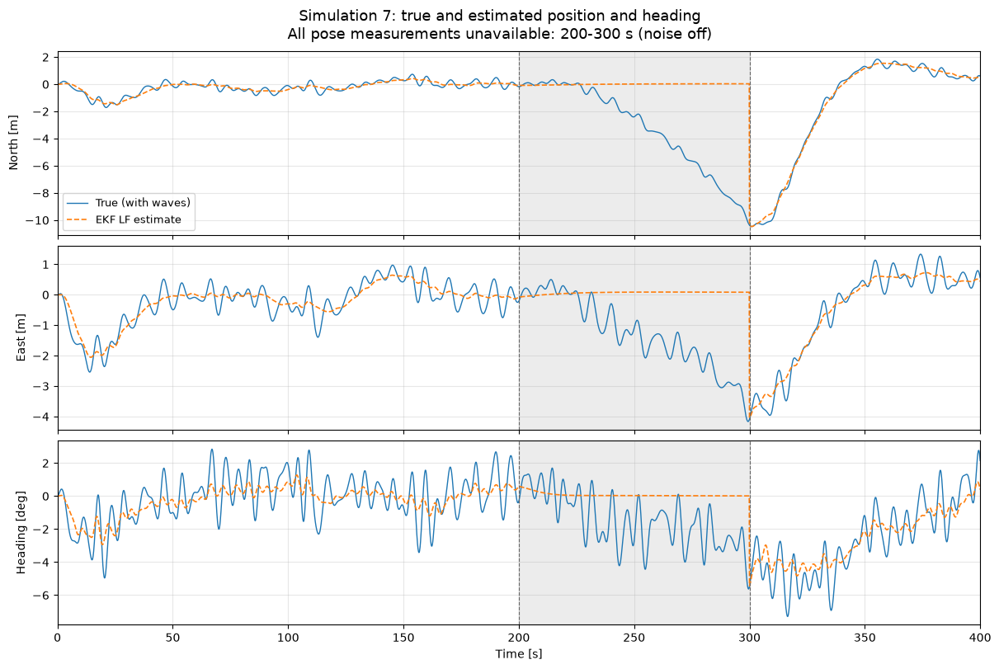

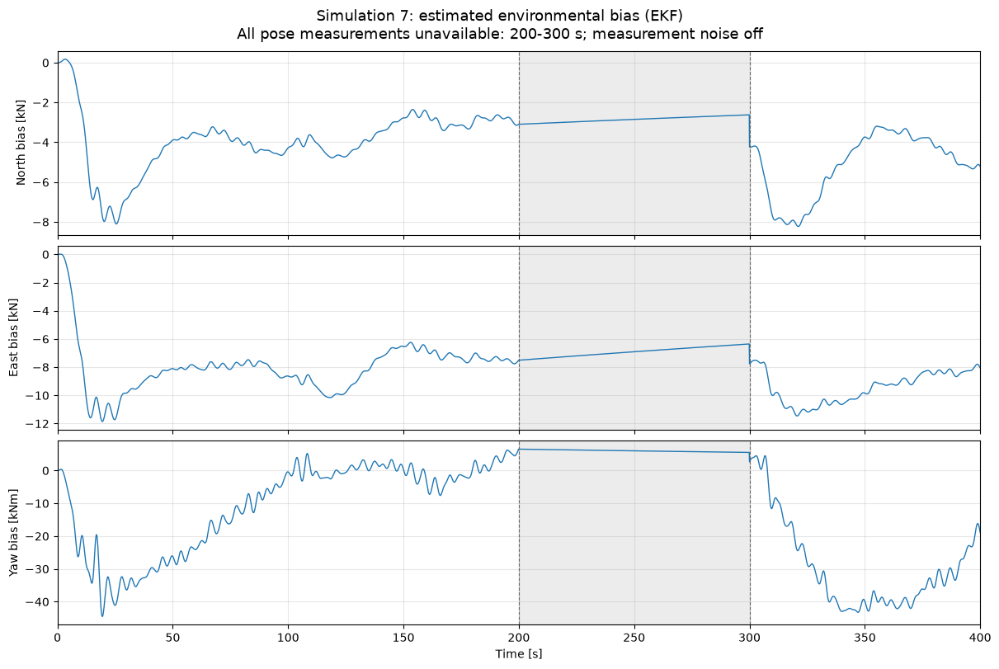

In [9]:
try:
    logs_7 = rc.sim7()
except NotImplementedError as exc:
    print('SKIPPED —', exc)

## Extra credit (3 points) — Sensor Noise

Optional. All regular simulations use ideal measurements; here the fixed
course noise levels of `models/sensors.py` are switched on
(`use_sensor_noise=True`) and the Part 2, Simulation 4 comparison plus the
raw-vs-observer closed loop are repeated. Discuss how measurement noise
changes the observer tuning trade-off and the thruster activity.

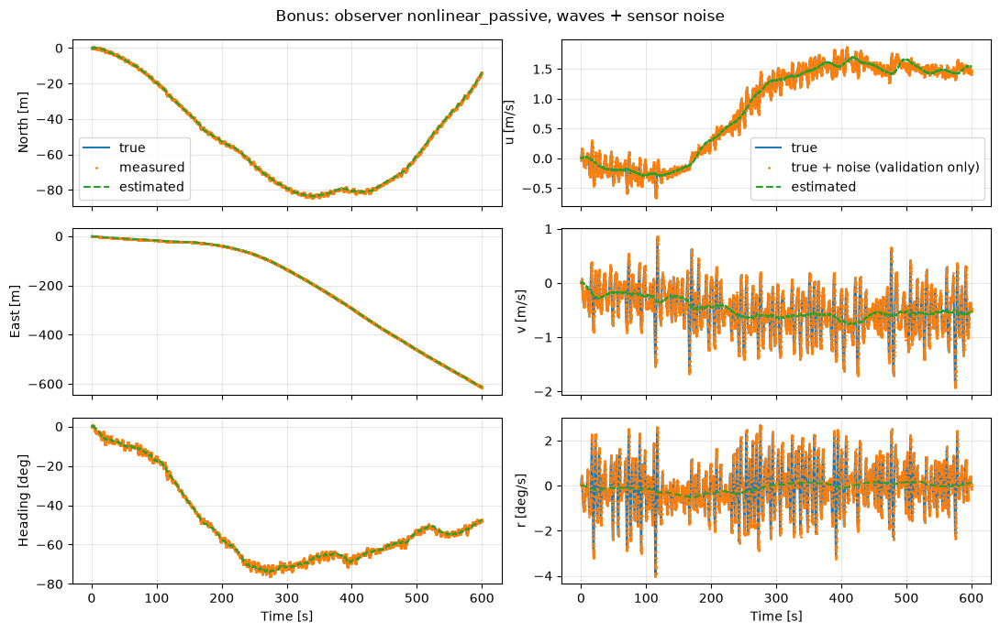

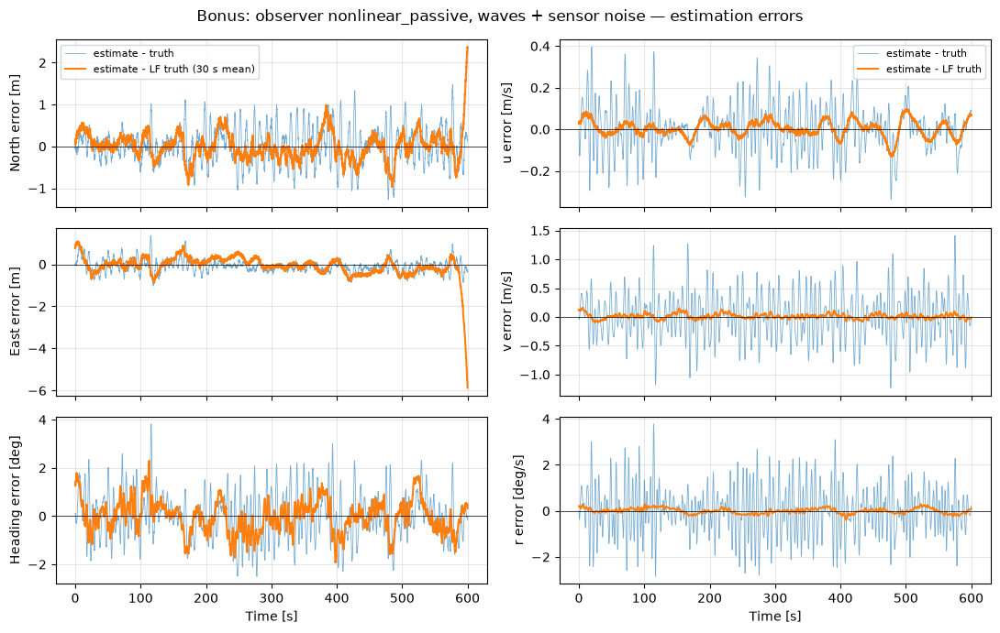

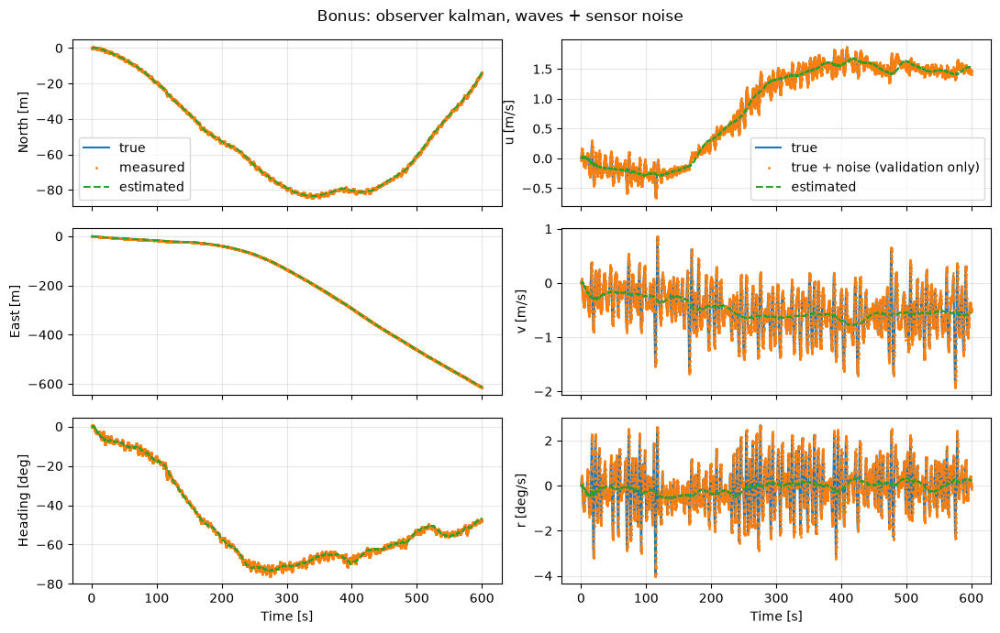

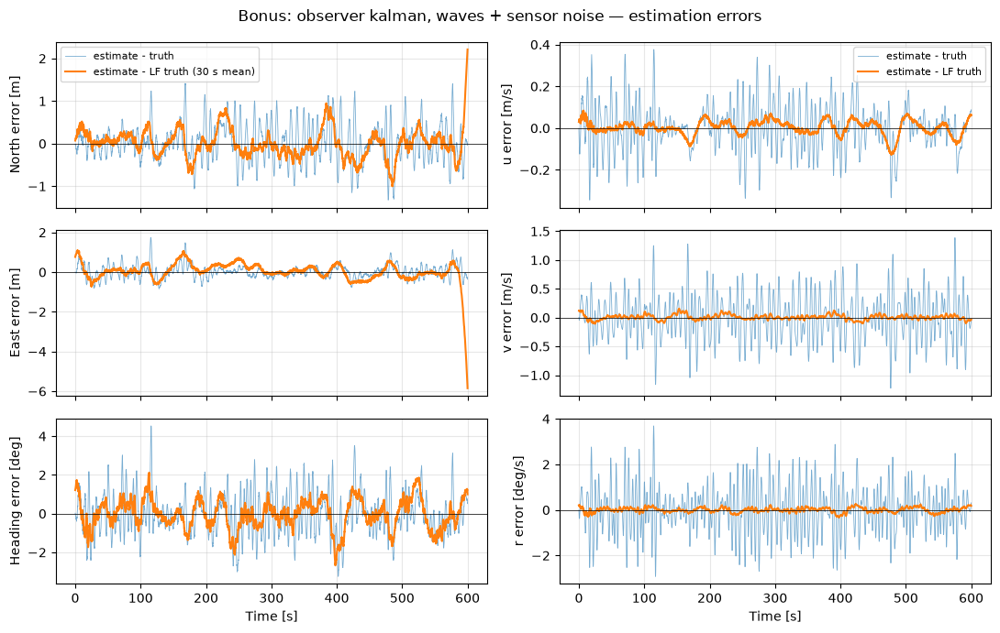

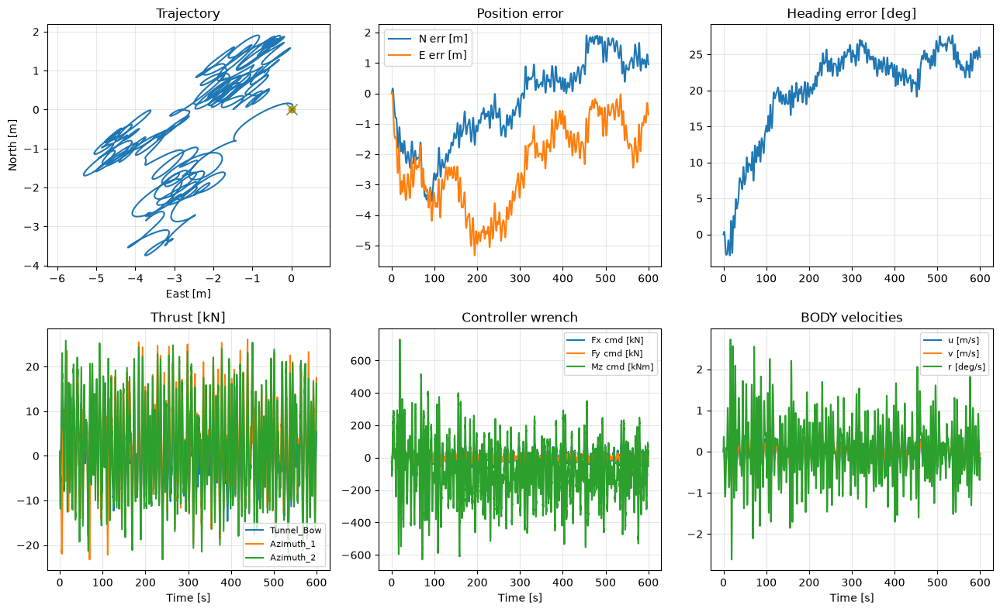

...

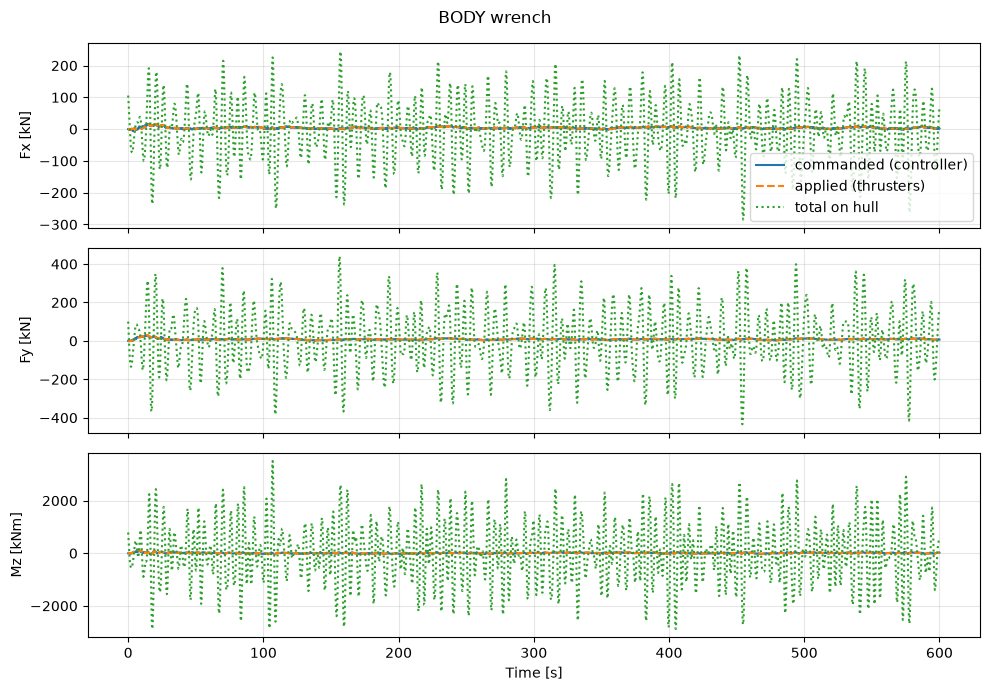

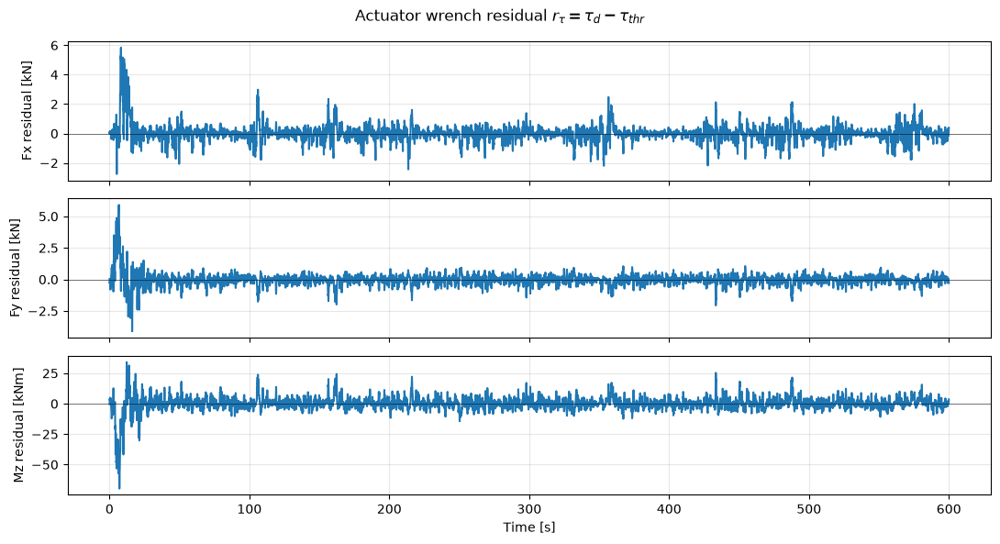

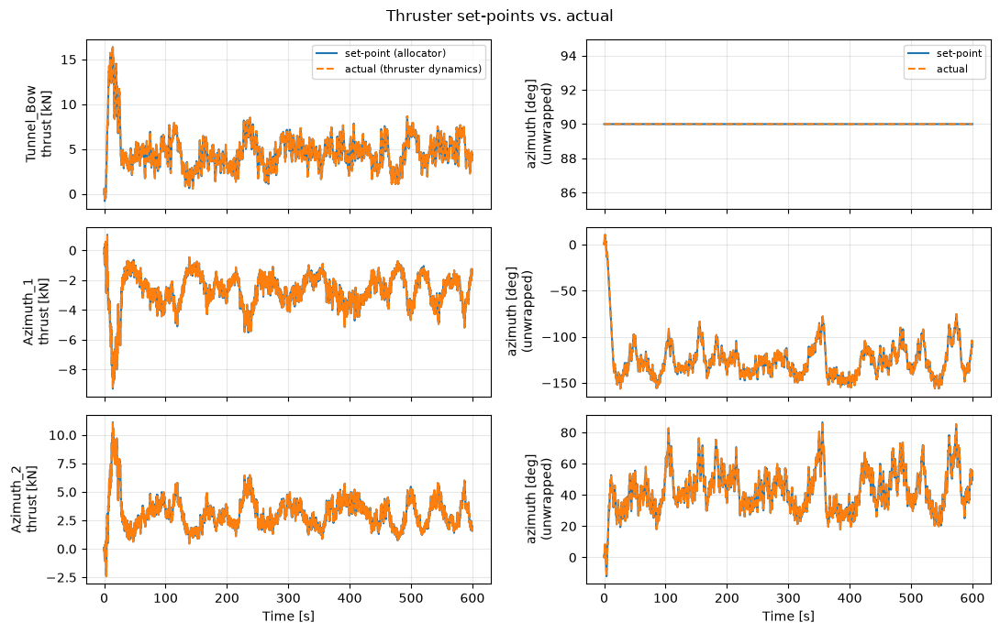

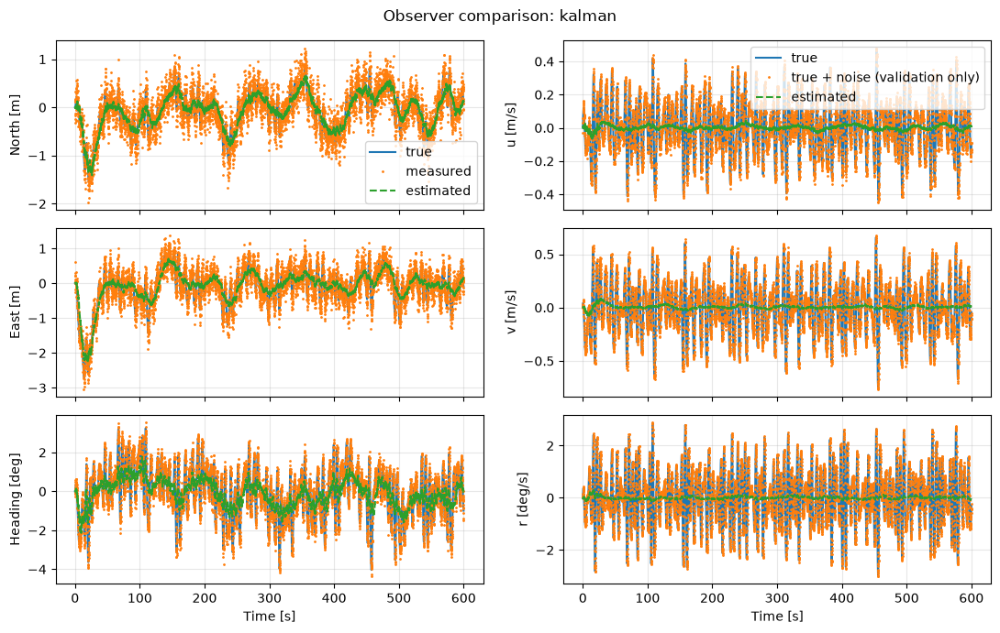

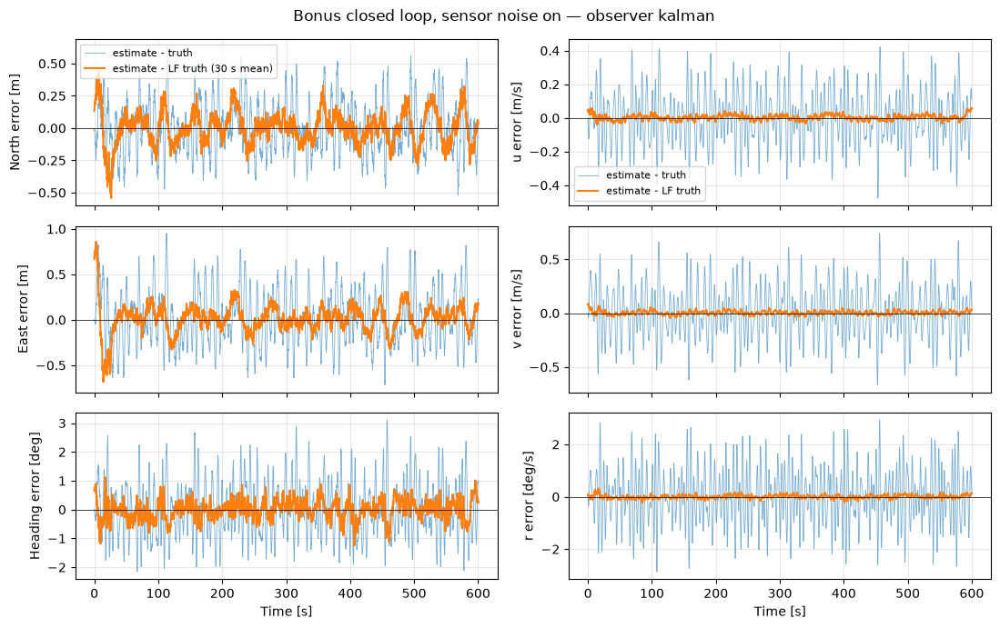

In [10]:
try:
    logs_bonus = rc.bonus_sensor_noise()
except NotImplementedError as exc:
    print('SKIPPED —', exc)

## Check summary

All statuses in one table (re-run the check cell first if you changed code).
When everything is `PASS`, `python check.py --part 2` and `pytest` are green too.

In [11]:
for key in ALL_CHECKS:
    r = results.get(key)
    print(f"[{r.status if r else 'not run':^15}] {r.name if r else key}")

[     PASS      ] current (part_2): direction conventions
[     PASS      ] wind (part_2): loads, gust, direction variation
[     PASS      ] allocation (part_2): wrenches and thruster limits
[     PASS      ] thrust utilisation (part_2/utilization.py): definition and averaging window
[     PASS      ] controller (part_2): sign tests and heading wrap
[     PASS      ] reference model (part_2): smooth step and heading wrap
[     PASS      ] observer 'nonlinear_passive': interface, filtering acts, heading wrap
[     PASS      ] observer 'kalman': interface, filtering acts, heading wrap


## Before the report

- Every figure needs readable axis labels with units, legends where needed, and
  a **discussion in the text**.
- The checks build your classes with their **default constructors** — keep
  your tuned parameters as the defaults in `part_2/`.
- The Part 2 report is **self-contained**: it is read and graded on its own.
  Copy the Part 1 material that still applies straight into it — text,
  equations, tables and figures — shortening or revising where useful, and
  mark what Part 2 changed. Pointing the reader at your Part 1 report instead
  of including the material is **not sufficient**.
- The appendix must explain how to reproduce every run
  (`python run_case_part_2.py simN`).